In [2]:
!ls /kaggle/input/datasets/laksimiaymane/mentale-chez-les-tudiants

README.md  student_mental_health.csv


In [3]:
import pandas as pd
df = pd.read_csv('/kaggle/input/datasets/laksimiaymane/mentale-chez-les-tudiants/student_mental_health.csv')
df.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


comprendre la structure générale du jeu de données (types de données, dimensions, aperçus) ;

In [4]:
print(df.shape)
print("--------------------------------------------------------------------")
print(df.dtypes)
print("---------------------------------------------------------------------")
print(df.head())
print("---------------------------------------------------------------------")
print(df.tail())
print("---------------------------------------------------------------------")


(2000, 17)
--------------------------------------------------------------------
Student_ID                         object
Age                                 int64
Gender                             object
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                  object
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                      object
Diet_Quality                       object
Previous_Mental_Health_History     object
Mental_Health_Risk                 object
dtype: object
---------------------------------------------------------------------
  Student_ID  Age  Gender  Year_of_Study  Sleep_Hours  Study_Hours_Per_Week  \
0    STU0001   22    Male              3   

Vérifier les valeurs manquantes, les doublons, les incohérences et les valeurs aberrantes.


In [5]:
print(df.isna().sum())
print("-----------------------------------")
print(df.isna().sum().sum())
print("-----------------------------------")
print(df.duplicated().sum().sum())
print("-----------------------------------")


Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64
-----------------------------------
419
-----------------------------------
0
-----------------------------------


In [6]:
import numpy as np
categorical_ent = df.select_dtypes(include=object)
categorical_ent.columns
df['Gender'] = categorical_ent['Gender'].astype('str').str.strip().str.upper()
# df['Gender'] = categorical_ent['Gender'].replace('Non-binary', np.nan)
# strict_map {
#     'Male': 'Male','M','Male'
# }
print(df['Gender'].head(20))
print(df['Gender'].tail(20))



0           MALE
1           MALE
2           MALE
3           MALE
4         FEMALE
5         FEMALE
6           MALE
7     NON-BINARY
8         FEMALE
9           MALE
10          MALE
11        FEMALE
12        FEMALE
13        FEMALE
14          MALE
15          MALE
16          MALE
17          MALE
18          MALE
19          MALE
Name: Gender, dtype: object
1980    FEMALE
1981      MALE
1982      MALE
1983      MALE
1984      MALE
1985      MALE
1986    FEMALE
1987    FEMALE
1988      MALE
1989    FEMALE
1990      MALE
1991      MALE
1992      MALE
1993    FEMALE
1994      MALE
1995      MALE
1996      MALE
1997    FEMALE
1998      MALE
1999    FEMALE
Name: Gender, dtype: object


In [7]:
# conditions = {
#     'Age': (df['Age'] < 0),
#     'Sleep_Hours': (df['Sleep_Hours'] < 0) | (df['Sleep_Hours'] > 24),
#     'Attendance_Rate': (df['Attendance_Rate'] < 0) | (df['Attendance_Rate'] > 100),
#     'GPA': (df['GPA'] < 0) | (df['GPA'] > 4),
#     'Year_of_Study': (df['Year_of_Study'] < 1) | (df['Year_of_Study'] > 5)
# }

# for col, condition in conditions.items():
#     print(f"{col}: {condition.sum()} invalid val")

In [8]:
numerical_feat = df.select_dtypes(include='number')
Q1 = numerical_feat.quantile(0.25)
Q3 = numerical_feat.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR 

is_high = numerical_feat > upper_bound
is_low = numerical_feat < lower_bound 
is_outlier = is_high | is_low 
       
v = numerical_feat[is_outlier[['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA',
       'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate']]]
v.stack()

# is_outlier.sum()

22    Social_Media_Hours     2.40
36    Attendance_Rate       61.10
180   Social_Media_Hours     9.00
209   Age                   29.00
217   Social_Media_Hours     2.80
                            ...  
1754  Screen_Time_Hours     14.00
1923  GPA                    3.51
1956  Social_Media_Hours     9.20
1957  Age                   28.00
1982  Sleep_Hours            3.30
Length: 61, dtype: float64

In [9]:
numerical_feat['Age'].describe()

df[(numerical_feat['Age'] >= 23) & (numerical_feat['Age'] <= 29)]['Age'].value_counts()
# df[numerical_feat['Age'] > 23] 
print(df.columns)
sum = df.groupby('Mental_Health_Risk')['Age'].mean()
fl = df[df['Social_Media_Hours'] > 5]

fl.groupby('Mental_Health_Risk')['Social_Media_Hours'].describe()

Index(['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Sleep_Hours',
       'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours',
       'Screen_Time_Hours', 'Physical_Activity', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate', 'Part_Time_Job', 'Diet_Quality',
       'Previous_Mental_Health_History', 'Mental_Health_Risk'],
      dtype='object')


,count,mean,std,min,25%,50%,75%,max
Mental_Health_Risk,,,,,,,,
High,578.0,6.609343,0.956769,5.1,5.8,6.5,7.2,10.0
Low,475.0,6.274737,0.851899,5.1,5.6,6.1,6.8,10.0
Medium,505.0,6.312277,0.814287,5.1,5.7,6.2,6.7,9.4


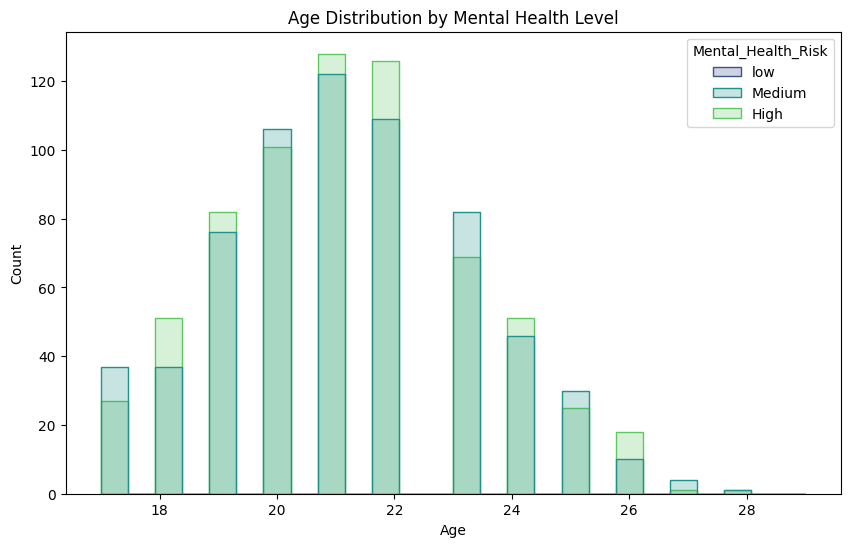

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set the figure size
plt.figure(figsize=(10, 6))

# Plot the histogram divided by the three classes
sns.histplot(
    data=df, 
    x='Age', 
    hue='Mental_Health_Risk',      # Replace with your exact column name
    hue_order=['low', 'Medium', 'High'], # Optional: forces a logical order
                # Optional: adds smooth density curves
    element='step',           # Makes overlapping bars easier to read
    palette='viridis'
)

plt.title('Age Distribution by Mental Health Level')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

In [11]:
df1 = df[df['Age'] == 23]
df1['Mental_Health_Risk'].value_counts()

Mental_Health_Risk
Medium    82
Low       82
High      69
Name: count, dtype: int64

In [12]:
df1 = df[df['Age'] == 27]
df1['Mental_Health_Risk'].value_counts()

Mental_Health_Risk
Low       5
Medium    4
High      1
Name: count, dtype: int64

Examiner les corrélations entre les variables.


In [13]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Convert the target into ordinal numerical values
df_corr = df.copy()

df_corr['Mental_Health_Risk'] = df_corr['Mental_Health_Risk'].map({
    'Low': 0,
    'Medium': 1,
    'High': 2
})

# Select numerical features
corr = df_corr.select_dtypes(include='number').drop(
    columns=['Student_ID'],
    errors='ignore'
).corr(method='pearson')

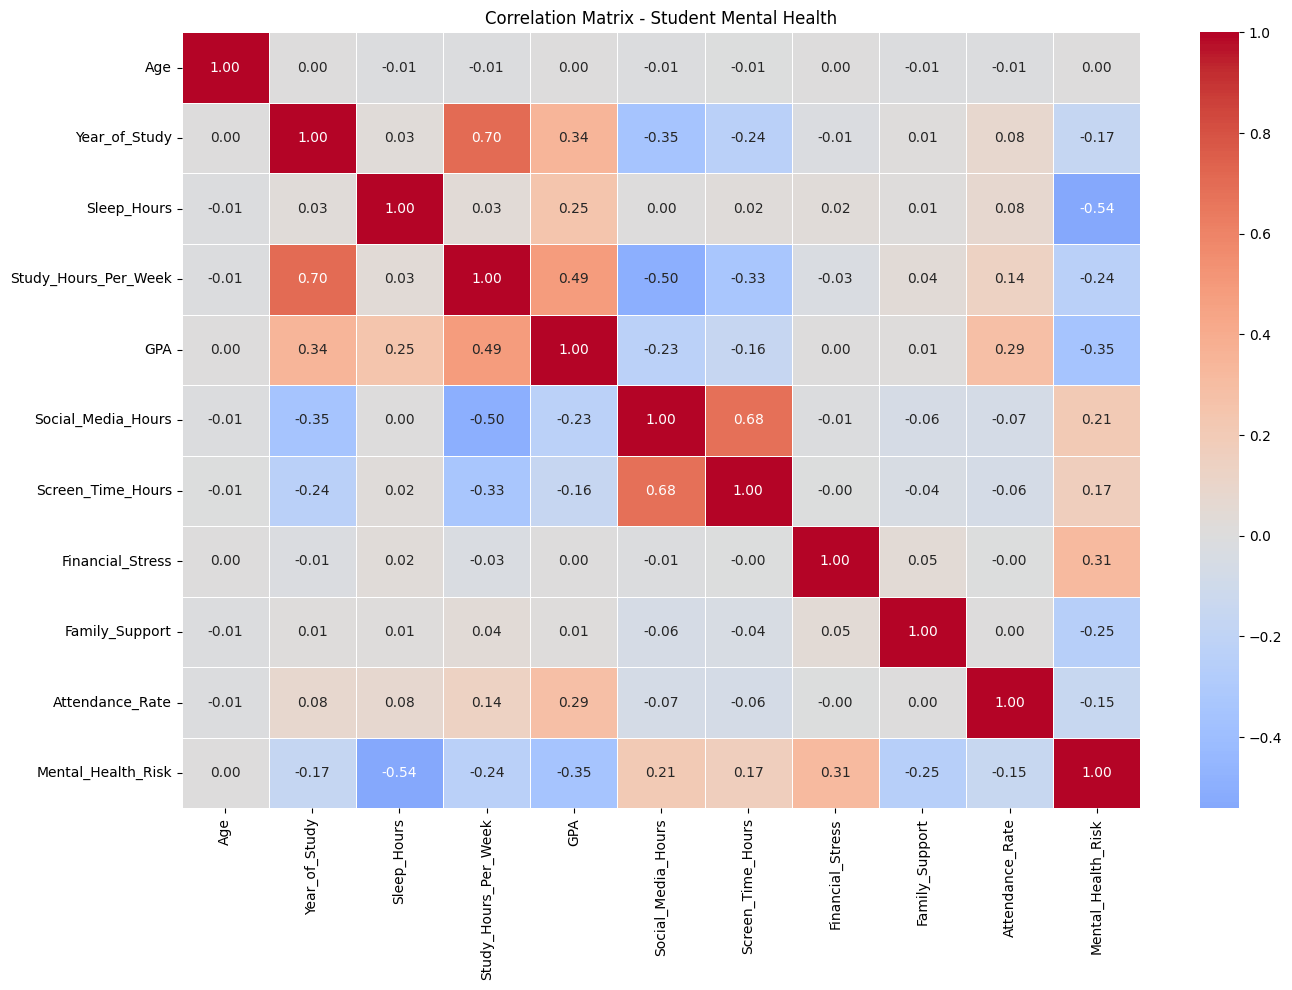

In [14]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Matrix - Student Mental Health')
plt.tight_layout()
plt.show()

identifier les variables les plus fortement liées au niveau de risque ;


In [15]:
risk_corr = corr['Mental_Health_Risk'].drop(
    'Mental_Health_Risk'
)

risk_corr = risk_corr.sort_values(
    key=abs,
    ascending=False
)

print(risk_corr)

Sleep_Hours            -0.541857
GPA                    -0.352626
Financial_Stress        0.313547
Family_Support         -0.250894
Study_Hours_Per_Week   -0.238793
Social_Media_Hours      0.207601
Screen_Time_Hours       0.173972
Year_of_Study          -0.166404
Attendance_Rate        -0.145362
Age                     0.004961
Name: Mental_Health_Risk, dtype: float64


Diviser les données en deux ensembles : un ensemble d’entraînement (80 %) et un ensemble de test (20 %).


In [16]:
df.columns

Index(['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Sleep_Hours',
       'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours',
       'Screen_Time_Hours', 'Physical_Activity', 'Financial_Stress',
       'Family_Support', 'Attendance_Rate', 'Part_Time_Job', 'Diet_Quality',
       'Previous_Mental_Health_History', 'Mental_Health_Risk'],
      dtype='object')

Diviser les données en deux ensembles : un ensemble d’entraînement (80 %) et un ensemble de test (20 %).


In [22]:
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler

# print(df.columns)
# df.drop("Student_ID",axis=1)
X = df.drop(["Mental_Health_Risk", 'Student_ID'],axis=1)
y = df["Mental_Health_Risk"]
# X = pd.get_dummies(X, drop_first=True)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numerical_features = X_train.select_dtypes(
    include='number'
).columns

categorical_features = X_train.select_dtypes(
    exclude='number'
).columns

from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer
numerical_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('imputer', KNNImputer(n_neighbors=5))
])
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

from sklearn.compose import ColumnTransformer 

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

X_train_pre = preprocessor.fit_transform(X_train)
X_test_pre = preprocessor.transform(X_test)

print(X_train.shape)
print(X_test.shape)
print(X_train_pre.shape)
print(X_test_pre.shape)

(1600, 15)
(400, 15)
(1600, 23)
(400, 23)
